In [1]:
import os, warnings
os.environ["TF_CPP_MIN_LOG_LEVEL"] = "2"    # hide TensorFlow startup logs
warnings.filterwarnings("ignore")           # hide library version warnings

In [2]:
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import yfinance as yf

In [3]:
# figure colors: actual data, AR, NN, reference lines
c_actual, c_ar, c_nn, c_ref = "#52514e", "#eb6834", "#2a78d6", "#898781"

plt.rcParams["figure.figsize"] = (10, 4)
plt.rcParams["axes.grid"] = True
plt.rcParams["grid.color"] = "#e1e0d9"
plt.rcParams["axes.spines.top"] = False
plt.rcParams["axes.spines.right"] = False

In [4]:
tickers = ["AAPL", "AMZN", "GOOGL", "JNJ", "JPM", "KO", "MSFT", "NVDA", "WMT", "XOM"]

data = yf.download(tickers, start="2010-01-01", end="2026-11-21")

[*********************100%***********************]  10 of 10 completed


In [5]:
close = data["Close"]
volume = data["Volume"]

In [6]:
close

Ticker,AAPL,AMZN,GOOGL,JNJ,JPM,KO,MSFT,NVDA,WMT,XOM
Date,,,,,,,,,,
2010-01-04,6.396101,6.695000,15.536592,39.778637,28.012629,17.103191,22.939930,0.422817,12.878357,36.903889
2010-01-05,6.407158,6.734500,15.468175,39.317368,28.555235,16.896299,22.947334,0.428992,12.750119,37.047977
2010-01-06,6.305244,6.612500,15.078242,39.637173,28.712112,16.890303,22.806519,0.431736,12.721626,37.368168
2010-01-07,6.293587,6.500000,14.727226,39.354279,29.280867,16.848322,22.569328,0.423275,12.728749,37.250774
2010-01-08,6.335429,6.676000,14.923558,39.489578,29.208960,16.536482,22.724977,0.424189,12.664626,37.101330
...,...,...,...,...,...,...,...,...,...,...
2026-11-16,352.779999,257.750000,283.720001,282.549988,338.209991,99.480003,516.991272,156.139999,128.410004,166.869995
2026-11-17,351.910004,257.890015,280.200012,278.700012,329.959991,98.790001,505.263947,155.460007,127.519997,167.210007
2026-11-18,352.450012,267.739990,282.440002,272.700012,324.109985,98.089996,507.309998,150.960007,127.360001,160.580002


In [7]:
volume

Ticker,AAPL,AMZN,GOOGL,JNJ,JPM,KO,MSFT,NVDA,WMT,XOM
Date,,,,,,,,,,
2010-01-04,493729600,151998000,78169752,9506200,35460500,13870400,38409100,800204000,62259300,27809100
2010-01-05,601904800,177038000,120067812,10673100,41208300,23172400,49749600,728648000,46945200,30174700
2010-01-06,552160000,143576000,158988852,13171500,27729000,19264600,58182400,649168000,37551600,35044700
2010-01-07,477131200,220604000,256315428,10901600,44864700,13234600,50559700,547792000,31988100,27192100
2010-01-08,447610800,196610000,188783028,7898000,33110100,28712400,51197400,478168000,34089600,24891800
...,...,...,...,...,...,...,...,...,...,...
2026-11-16,50292200,48054200,34747200,8101700,7250300,19154600,30218600,333822100,17780200,14286200
2026-11-17,37407500,38685200,32175900,8973500,8210200,19066200,27992800,406985100,19841300,11955200
2026-11-18,34209900,41289500,27401800,7935200,6778200,16554000,22050100,349791400,27962700,18122000


In [8]:
ret = close.pct_change().dropna()          # daily return
dvol = np.log(volume).diff().dropna()      # daily change in log volume

In [9]:
rng = ((data["High"] - data["Low"]) / close).loc[ret.index]
log_rng = np.log(rng.where(rng > 0))

In [10]:
train_start, fit_end = "2010-06-01", "2023-12-31"
test_start, test_end = "2024-01-01", "2026-11-20"

In [11]:
def make_xy(y, start, end):
    # Predict today's log range from yesterday, the past week, and the past month
    X = pd.DataFrame({
        "bias":  1.0,
        "day":   y.shift(1),
        "week":  y.rolling(5).mean().shift(1),
        "month": y.rolling(22).mean().shift(1),
    })
    X, y = X[start:end], y[start:end]
    keep = X.notna().all(axis=1) & y.notna()
    return X[keep].values, y[keep].values, y[keep].index

In [12]:
t = "AAPL"
X, y, _ = make_xy(log_rng[t], train_start, fit_end)
n, p = X.shape

In [13]:
# ---------- 2. OLS (starting point for the chain) ----------
w_hat = np.linalg.inv(X.T @ X) @ (X.T @ y)
resid = y - X @ w_hat
sigma2_hat = (resid @ resid) / (n - p)
print("OLS estimates (w_hat):", w_hat)
print("OLS sigma^2:", sigma2_hat)

OLS estimates (w_hat): [-0.58383212  0.26898619  0.27882825  0.30833308]
OLS sigma^2: 0.1632175172051266


In [14]:
prior_w = np.zeros(p)
prior_Sigma = np.eye(p) * 100             # w ~ N(0, 100 I)
inv_prior_Sigma = np.linalg.inv(prior_Sigma)
prior_alpha, prior_beta = 3, 1            # sigma^2 ~ InvGamma(3, 1)

def log_posterior(w, sigma2, X, y):
    if sigma2 <= 0:
        return -np.inf                    # impossible value, always rejected
    resid = y - X @ w
    log_lik = -len(y) / 2 * np.log(sigma2) - (resid @ resid) / (2 * sigma2)
    log_prior_w = -0.5 * (w - prior_w) @ inv_prior_Sigma @ (w - prior_w)
    log_prior_sigma2 = -(prior_alpha + 1) * np.log(sigma2) - prior_beta / sigma2
    return log_lik + log_prior_w + log_prior_sigma2

In [15]:
prop_cov_w = (2.38 ** 2 / (p + 1)) * sigma2_hat * np.linalg.inv(X.T @ X)
prop_sd_sigma2 = (2.38 / np.sqrt(p + 1)) * sigma2_hat * np.sqrt(2 / n)

def metropolis(X, y, w_start, sigma2_start, prop_cov_w, prop_sd_sigma2,
               num_samples=10000, seed=0):
    np.random.seed(seed)
    samples_w = np.zeros((num_samples, X.shape[1]))
    samples_sigma2 = np.zeros(num_samples)

    w_current, sigma2_current = w_start.copy(), sigma2_start
    lp_current = log_posterior(w_current, sigma2_current, X, y)
    accepted = 0

    for i in range(num_samples):
        # propose a new point near the current one
        w_prop = np.random.multivariate_normal(w_current, prop_cov_w)
        sigma2_prop = sigma2_current + np.random.normal(0, prop_sd_sigma2)
        lp_prop = log_posterior(w_prop, sigma2_prop, X, y)

        # accept with probability min(1, posterior ratio), compared on the log scale
        if np.log(np.random.uniform()) < lp_prop - lp_current:
            w_current, sigma2_current, lp_current = w_prop, sigma2_prop, lp_prop
            accepted += 1

        samples_w[i, :] = w_current
        samples_sigma2[i] = sigma2_current

    return samples_w, samples_sigma2, accepted / num_samples

samples_w, samples_sigma2, acc = metropolis(X, y, w_hat, sigma2_hat, prop_cov_w, prop_sd_sigma2)
print("Acceptance rate:", acc)

Acceptance rate: 0.2903


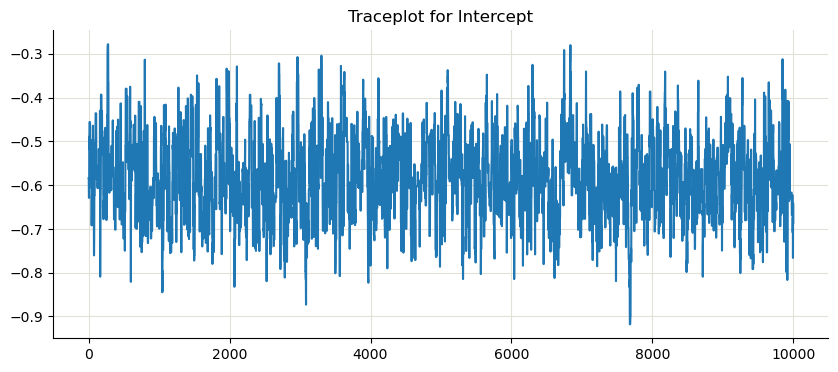

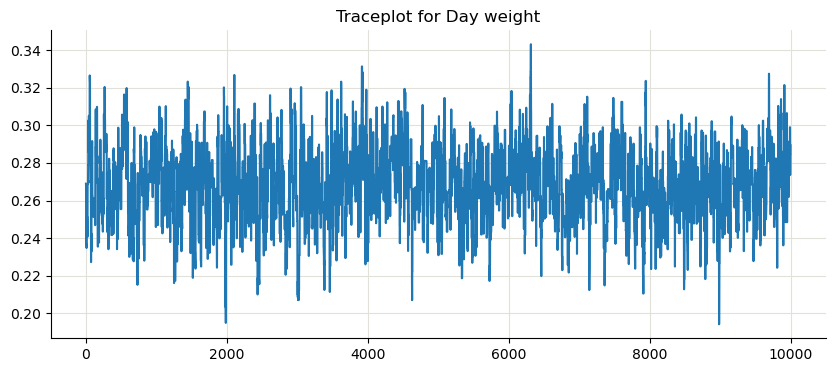

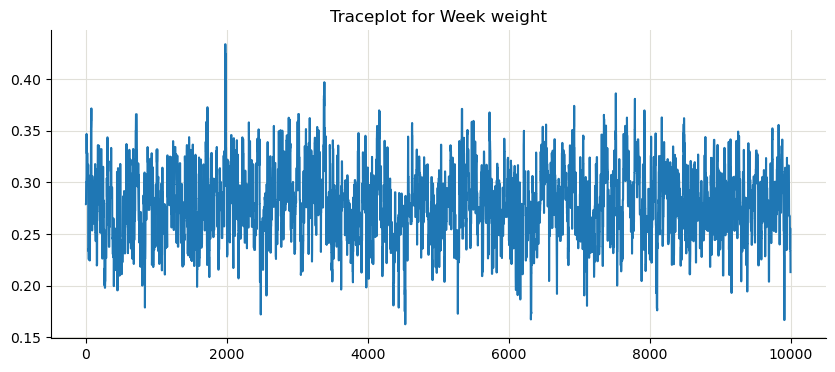

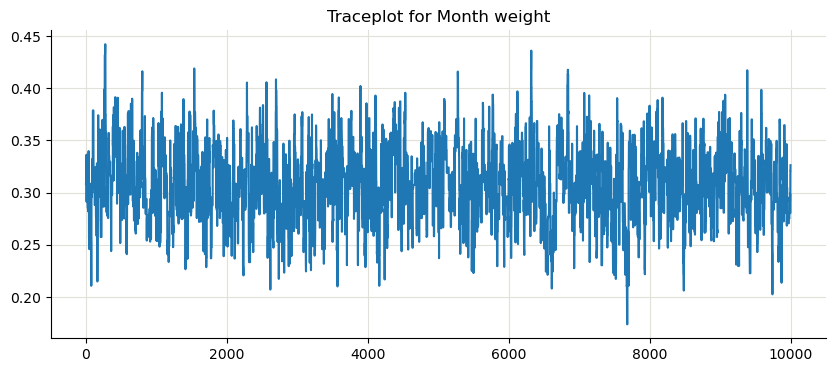

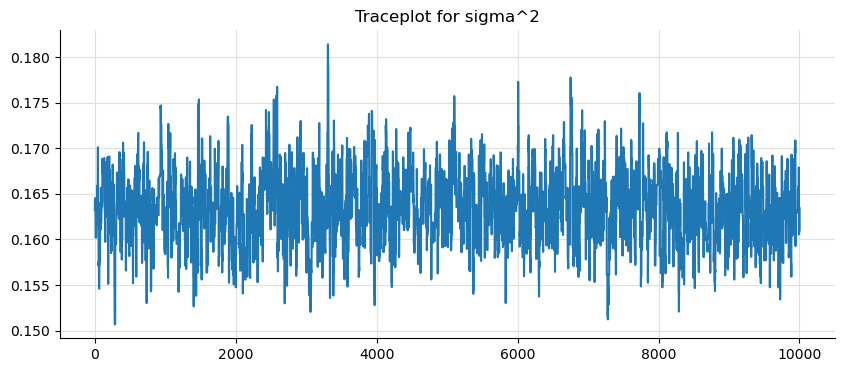

In [16]:
names = ["Intercept", "Day weight", "Week weight", "Month weight"]
for k in range(p):
    plt.figure()
    plt.plot(samples_w[:, k])
    plt.title(f"Traceplot for {names[k]}")
    plt.show()
plt.figure()
plt.plot(samples_sigma2)
plt.title("Traceplot for sigma^2")
plt.show()

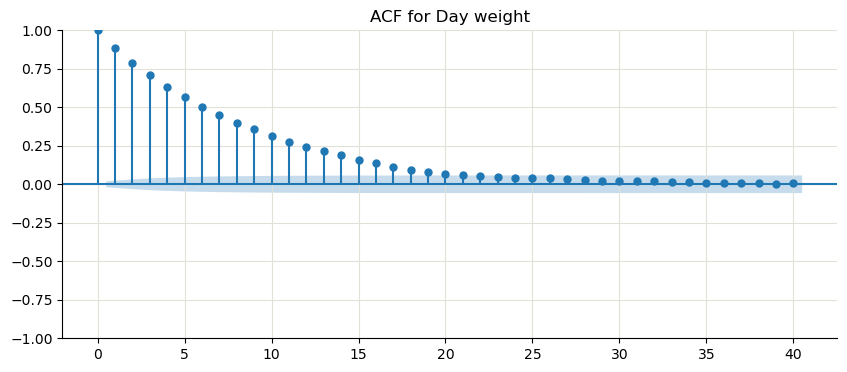

In [17]:
from statsmodels.graphics.tsaplots import plot_acf

plot_acf(samples_w[:, 1])
plt.title("ACF for Day weight")
plt.show()

In [18]:
burn, thin = 2000, 5
post_w = samples_w[burn::thin]
post_sigma2 = samples_sigma2[burn::thin]
print("Posterior means:", post_w.mean(axis=0), post_sigma2.mean())


Posterior means: [-0.5857941   0.26859744  0.28023951  0.30682604] 0.16357963134389195


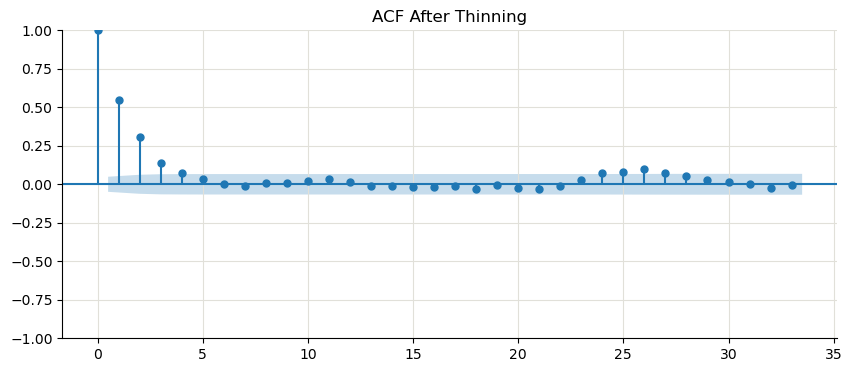

In [19]:
plot_acf(post_w[:, 1])
plt.title("ACF After Thinning")
plt.show()

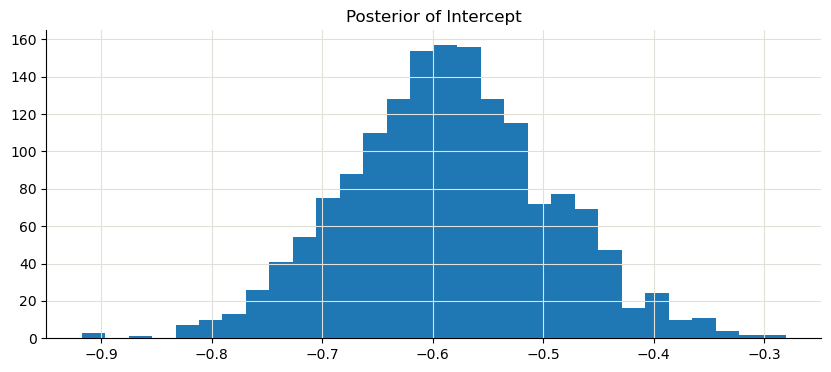

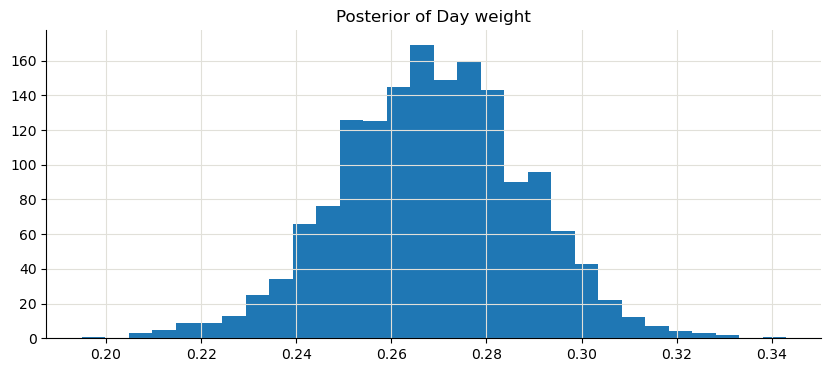

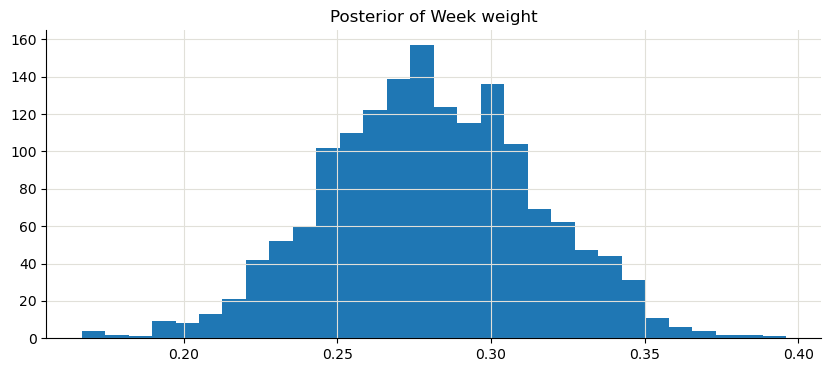

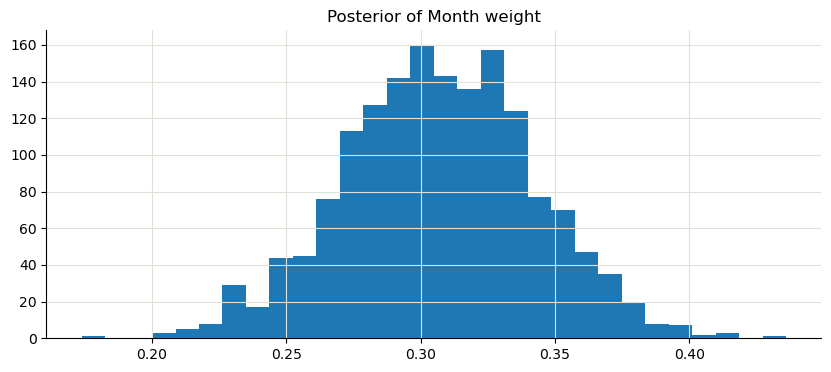

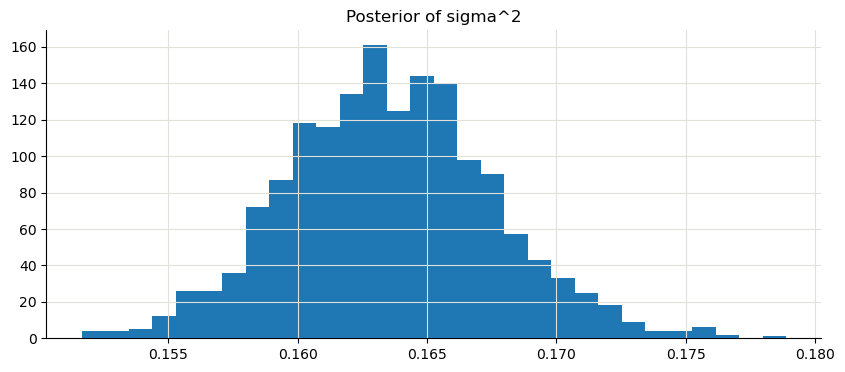

In [20]:
for k in range(p):
    plt.figure()
    plt.hist(post_w[:, k], bins=30)
    plt.title(f"Posterior of {names[k]}")
    plt.show()
plt.figure()
plt.hist(post_sigma2, bins=30)
plt.title("Posterior of sigma^2")
plt.show()

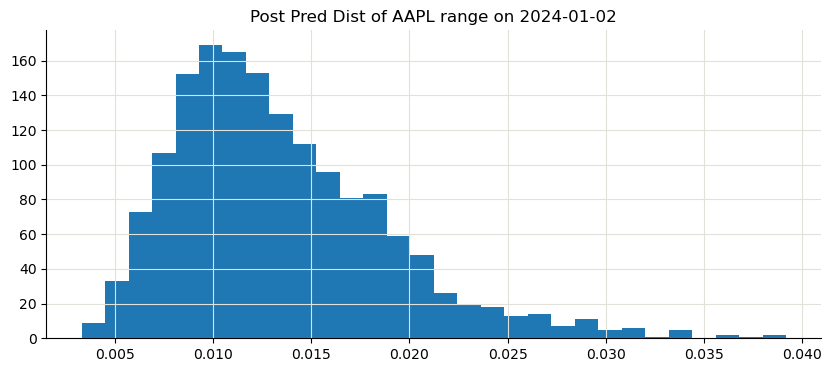

Predictive mean: 0.01344628170770491
Actual range: 0.024509820441270338


In [21]:
X_test, y_test, test_idx = make_xy(log_rng[t], test_start, test_end)
day_hat = []
for i in range(len(post_w)):
    mean_pred = X_test[0, :] @ post_w[i, :]
    day_hat.append(np.exp(np.random.normal(mean_pred, np.sqrt(post_sigma2[i]))))
day_hat = np.array(day_hat)
plt.figure()
plt.hist(day_hat, bins=30)
plt.title(f"Post Pred Dist of {t} range on {test_idx[0].date()}")
plt.show()
print("Predictive mean:", day_hat.mean())
print("Actual range:", np.exp(y_test[0]))

In [22]:
def predict(post_w, post_sigma2, X_test):
    # each row = one test day, each column = one posterior draw
    mean_pred = X_test @ post_w.T
    sims = np.exp(mean_pred + np.sqrt(post_sigma2) * np.random.normal(size=mean_pred.shape))
    point = sims.mean(axis=1)                             # posterior predictive mean
    lo = np.percentile(sims, 5, axis=1)                   # 90% predictive interval
    hi = np.percentile(sims, 95, axis=1)
    return point, lo, hi

In [23]:
pred_avg = rng.rolling(20).mean().shift(1)                # same baseline as the AR/NN notebook

rows = []
for t in tickers:
    X, y, _ = make_xy(log_rng[t], train_start, fit_end)
    n, p = X.shape
    w_hat = np.linalg.inv(X.T @ X) @ (X.T @ y)
    resid = y - X @ w_hat
    sigma2_hat = (resid @ resid) / (n - p)
    prop_cov_w = (2.38 ** 2 / (p + 1)) * sigma2_hat * np.linalg.inv(X.T @ X)
    prop_sd_sigma2 = (2.38 / np.sqrt(p + 1)) * sigma2_hat * np.sqrt(2 / n)

    samples_w, samples_sigma2, acc = metropolis(X, y, w_hat, sigma2_hat, prop_cov_w, prop_sd_sigma2)
    post_w, post_sigma2 = samples_w[burn::thin], samples_sigma2[burn::thin]

    X_test, _, test_idx = make_xy(log_rng[t], test_start, test_end)
    point, lo, hi = predict(post_w, post_sigma2, X_test)
    actual = rng[t].loc[test_idx].values
    baseline = pred_avg[t].loc[test_idx].values

    rows.append({
        "ticker": t,
        "acceptance": acc,
        "MSE vs baseline": np.mean((actual - point) ** 2) / np.mean((actual - baseline) ** 2),
        "90% coverage": np.mean((actual >= lo) & (actual <= hi)),
    })

results_bayes = pd.DataFrame(rows).set_index("ticker")
print(results_bayes)

        acceptance  MSE vs baseline  90% coverage
ticker                                           
AAPL        0.2903         0.789093      0.918733
AMZN        0.2860         0.810024      0.891185
GOOGL       0.2860         0.939564      0.876033
JNJ         0.2828         0.915605      0.921488
JPM         0.2828         0.878729      0.893939
KO          0.2811         0.920030      0.903581
MSFT        0.2869         0.859688      0.903581
NVDA        0.2862         0.816619      0.893939
WMT         0.2854         0.860450      0.909091
XOM         0.2830         0.887205      0.900826
